# v3 - Leveraged beta (SPY / SSO / UPRO)

Robert Miller

After v2, the walk-forward version beat buy and hold SPY after taxes, but simply holding SSO (2x) still made more money. So the question for this version was whether I could beat buy and hold SSO after taxes in a regular brokerage account. It can hold SPY, SSO, UPRO (3x) and T-bills, which means leverage anywhere from 0 to 3x.

### Where the rules come from

I didn't want to just make up rules and tune them until something worked, so every rule here comes from a paper and uses the setting from that paper.

The trend filter comes from Gayed and Bilello (2016). They held a leveraged S&P 500 only when it was above its 200-day moving average (T-bills otherwise), and from 1928-2015 that beat both regular and leveraged buy and hold. Faber (2007) does basically the same thing with a 10-month average, so I test both.

For how often to check, Clare et al. (2013) found that for the S&P 500, checking at month end was as good as checking daily, and stop losses didn't help. Even though monthly is what I'm aiming for, I still test monthly, weekly and daily to see if that holds up here.

For how much leverage to use, I test fixed 2x or 3x and a Kelly-style rule, where leverage = k x risk premium / variance (Rotando and Thorp 1992). That's basically the same 1/variance scaling Moreira and Muir (2017) and Harvey et al. (2018) found raised the market's Sharpe ratio. I use a 6% premium, which is the middle of the 5-7% range from Zenner et al. (2008), with volatility from either the last 21 days or the VIX.

On the other hand, a couple of papers were basically warnings. Cederburg et al. (2020) found volatility management usually did not beat buy and hold out of sample, and Zakamulin (2014) found moving average timing mostly wins in a few big bear markets and lags in bull markets. In addition, leveraged ETFs reset every day, so they get hurt in choppy markets (Cheng and Madhavan 2009). For example, Bianchi and Goldberg (2026) point out the S&P was flat over 2022-2023 but UPRO lost 28%. The trend filter is supposed to keep the leverage on only when there's a trend.

That gives 42 combinations of trend filter, leverage rule and check frequency.

### Fees and taxes

$10,000 start, $0 commission, 5 bps of spread/slippage per dollar traded, and ETF fees are already in the prices (UPRO 0.91%, SSO 0.89%). Cash sits in SGOV at the T-bill rate minus 0.09%. Taxes are federal only: 22% on short-term gains, T-bill interest and SSO/UPRO payouts (leveraged funds mostly pay out short-term gains), 15% on long-term gains and SPY dividends, with tax lots, loss netting, carryforwards and the wash sale rule.

### Things I fixed from my first version

When I went back through my first version of this notebook, I found a few things that made it look better than it actually was:

- It traded at the same month-end close that created the signal. You can't actually do that, since you don't know the close until it happens. Trades now go in at the next day's close, which by itself took the 2005-now result from 16.9% down to about 14.7% a year.
- The walk-forward started in 2005, which skipped the year where it would have picked plain 3x right before the dot com crash. It now starts in 2000.
- I wasn't applying the wash sale rule, I was crediting the $3,000 loss deduction to the account (that money is really saved outside the account), and I was taxing SSO/UPRO payouts as qualified dividends. All three are fixed.
- My Monte Carlo was just reshuffling the strategy's own returns, so it could never show the trend filter failing. It now builds new price paths and re-runs the rule on each one.

I also added a significance test, a split between the years where UPRO is rebuilt vs real, a test outside the US, and a rolling-window version of the walk-forward. Those are all near the bottom.

### What this notebook reproduces

Most of the README comes from this notebook. Specifically, Section 2 uses the grid in the v3 row of README Table 2, Section 3 makes Figure 2 and the v3 fixed split result in Table 3, and Section 4 makes Figure 1, the walk-forward column of Table 3, and Table 4. In addition, Section 5 is Table 5, and the checks in Section 6 are README Sections 6.1-6.7 (including Table 6). It reads SPY, SSO, UPRO, the VIX, the Nikkei, the DAX and the T-bill rate from the `data/` folder, so run `python get_data.py` from the main folder first, and then run every cell from top to bottom. It saves both README charts into `images/`, and the last cell prints the package versions and data files it was run with.

In [1]:
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import strategy
from strategy import (load_data, get_target_leverage, get_target_weights, simulate, run_strategy,
                      run_fixed, get_stats, after_tax_cagr, block_bootstrap, get_settings_grid,
                      walk_forward, chosen_settings, start_value, tickers, trading_days)

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.width", 200)

data = load_data()
returns = data["total_return"]

print("First date:", data["dates"][0].date())
print("Last date:", data["dates"][-1].date())

First date: 1993-01-29
Last date: 2026-10-29


## 1. Checking the rebuilt SSO and UPRO

SSO started in June 2006 and UPRO in June 2009, so before that I rebuild them from SPY: leverage x SPY's daily return, minus the T-bill rate plus a spread on the borrowed part, minus the fund's fee. I picked the spread so the rebuilt fund grows at the same rate as the real one over the years where both exist.

In [2]:
for ticker, leverage, fee, spread in [("SSO", 2, strategy.sso_fee, strategy.sso_spread),
                                      ("UPRO", 3, strategy.upro_fee, strategy.upro_spread)]:

    overlap = returns.index > data["first_date"][ticker]
    real = returns.loc[overlap, ticker + "_actual"]
    base = leverage * returns.loc[overlap, "SPY"] - (leverage - 1) * data["tbill_return"][overlap]
    years = overlap.sum() / trading_days

    def rebuilt_growth(x):
        return (1 + base - ((leverage - 1) * x + fee) / trading_days).prod()

    spreads = np.arange(0, 0.0201, 0.0005)
    best = spreads[int(np.argmin([abs(rebuilt_growth(x) - (1 + real).prod()) for x in spreads]))]
    rebuilt = base - ((leverage - 1) * spread + fee) / trading_days

    print(ticker, "since", data["first_date"][ticker].date())
    print("  Real CAGR:", str(round(((1 + real).prod() ** (1 / years) - 1) * 100, 2)) + "%")
    print("  Best matching spread:", str(round(best * 100, 2)) + "%, saved in strategy.py:", str(round(spread * 100, 2)) + "%")
    print("  Correlation of daily returns:", round(rebuilt.corr(real), 4))

SSO since 2006-06-21
  Real CAGR: 15.68%
  Best matching spread: 0.7%, saved in strategy.py: 0.7%
  Correlation of daily returns: 0.9956
UPRO since 2009-06-25
  Real CAGR: 32.61%
  Best matching spread: 0.6%, saved in strategy.py: 0.6%
  Correlation of daily returns: 0.9983


## 2. Picking settings on 2000-2009

All 42 combinations, with taxes, ranked by after-tax CAGR (selling everything at the end of 2009).

The grid here is the v3 row of Table 2 in the README.

In [3]:
train_start = "2000-01-01"
train_end = "2009-12-31"
test_start = "2010-01-01"

settings_list = get_settings_grid()

results = []
for settings in settings_list:
    bt = run_strategy(data, settings, start=train_start, end=train_end, taxes=True)
    stats = get_stats(bt["strategy_return"], bt["tbill_return"], bt["spy_return"])
    row = dict(settings)
    row["after_tax_cagr"] = after_tax_cagr(bt)
    row["max_drawdown"] = stats["max_drawdown"]
    row["trades"] = int((bt["traded"] > 0).sum())
    results.append(row)

train_results = pd.DataFrame(results).sort_values("after_tax_cagr", ascending=False)

for ticker in ["SPY", "SSO", "UPRO"]:
    hold = run_fixed(data, {ticker: 1.0}, start=train_start, end=train_end, taxes=True)
    print("Buy and hold", ticker, "after-tax CAGR in training:", str(round(after_tax_cagr(hold) * 100, 2)) + "%")

train_results.head(12)

Buy and hold SPY after-tax CAGR in training: -1.18%
Buy and hold SSO after-tax CAGR in training: -10.92%
Buy and hold UPRO after-tax CAGR in training: -22.31%


,trend,sizing,size,vol_source,check,after_tax_cagr,max_drawdown,trades
21,sma200,fixed,3.000,realized,monthly,0.107,-0.426,7
37,sma10m,fixed,3.000,realized,monthly,0.106,-0.395,9
18,sma200,fixed,2.000,realized,monthly,0.087,-0.308,7
36,sma10m,fixed,2.000,realized,monthly,0.086,-0.260,9
27,sma200,kelly,1.000,realized,monthly,0.082,-0.338,41
39,sma10m,kelly,1.000,realized,monthly,0.076,-0.333,42
33,sma200,kelly,1.000,vix,monthly,0.065,-0.257,50
41,sma10m,kelly,1.000,vix,monthly,0.061,-0.245,50
24,sma200,kelly,0.500,realized,monthly,0.053,-0.214,59
38,sma10m,kelly,0.500,realized,monthly,0.050,-0.214,58


In [4]:
best = train_results.iloc[0]
best_settings = {
    "trend": best["trend"],
    "sizing": best["sizing"],
    "size": float(best["size"]),
    "vol_source": best["vol_source"],
    "check": best["check"],
}
print("Best settings on training data:", best_settings)
print("Settings saved in strategy.py:", chosen_settings)
if best_settings != chosen_settings:
    print("These do not match. Update chosen_settings in strategy.py so monthly_signal.py uses them.")

print()
print("Average training after-tax CAGR by how often it checks:")
print(train_results.groupby("check")["after_tax_cagr"].mean().round(4).to_string())
print()
print("Average training after-tax CAGR by trend filter:")
print(train_results.groupby("trend")["after_tax_cagr"].mean().round(4).to_string())

Best settings on training data: {'trend': 'sma200', 'sizing': 'fixed', 'size': 3.0, 'vol_source': 'realized', 'check': 'monthly'}
Settings saved in strategy.py: {'trend': 'sma200', 'sizing': 'fixed', 'size': 3.0, 'vol_source': 'realized', 'check': 'monthly'}

Average training after-tax CAGR by how often it checks:
check
daily     -0.031
monthly    0.025
weekly    -0.034

Average training after-tax CAGR by trend filter:
trend
none     -0.079
sma10m    0.070
sma200    0.038


## 3. Testing on 2010 to now

The setting is locked in from the training years. Compared to buy and hold SPY, SSO and UPRO, and the same rule at 2x.

This section makes Figure 2 (`images/drawdowns_2010.png`) and the v3 fixed split result in Table 3 of the README.

In [5]:
s = best_settings
same_rule_2x = dict(s)
same_rule_2x["size"] = 2.0

runs = {
    "Strategy": lambda tax: run_strategy(data, s, start=test_start, taxes=tax),
    "Same rule with 2x": lambda tax: run_strategy(data, same_rule_2x, start=test_start, taxes=tax),
    "Buy and hold SPY": lambda tax: run_fixed(data, {"SPY": 1.0}, start=test_start, taxes=tax),
    "Buy and hold SSO": lambda tax: run_fixed(data, {"SSO": 1.0}, start=test_start, taxes=tax),
    "Buy and hold UPRO": lambda tax: run_fixed(data, {"UPRO": 1.0}, start=test_start, taxes=tax),
}

pre_tax = {name: run(False) for name, run in runs.items()}
with_tax = {name: run(True) for name, run in runs.items()}


def make_table(pre, taxed_runs):
    table = {}
    for name in pre:
        bt = pre[name]
        taxed = taxed_runs[name]
        stats = get_stats(bt["strategy_return"], bt["tbill_return"], bt["spy_return"])
        table[name] = {
            "value_before_tax": bt["value"].iloc[-1],
            "value_after_tax_sold": taxed.attrs["liquidation_value"],
            "cagr_before_tax": stats["cagr"],
            "cagr_after_tax": after_tax_cagr(taxed),
            "volatility": stats["volatility"],
            "sharpe": stats["sharpe"],
            "max_drawdown": stats["max_drawdown"],
            "beta": stats["beta"],
        }
    return pd.DataFrame(table)


table = make_table(pre_tax, with_tax)
strategy_test = pre_tax["Strategy"]
print("Rebalances:", int((strategy_test["traded"] > 0).sum()), "in", round(len(strategy_test) / trading_days, 1), "years")
table

Rebalances: 29 in 16.8 years


,Strategy,Same rule with 2x,Buy and hold SPY,Buy and hold SSO,Buy and hold UPRO
value_before_tax,"139,481.160","81,757.392","91,144.331","311,165.088","725,134.483"
value_after_tax_sold,"96,681.207","60,608.061","76,769.447","261,801.029","611,415.255"
cagr_before_tax,0.170,0.133,0.141,0.227,0.291
cagr_after_tax,0.145,0.113,0.129,0.215,0.278
volatility,0.380,0.254,0.170,0.340,0.510
sharpe,0.567,0.563,0.772,0.730,0.730
max_drawdown,-0.642,-0.484,-0.337,-0.593,-0.768
beta,1.663,1.112,0.999,1.997,2.989


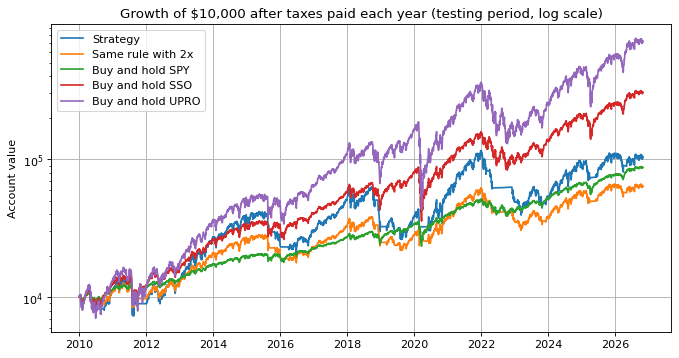

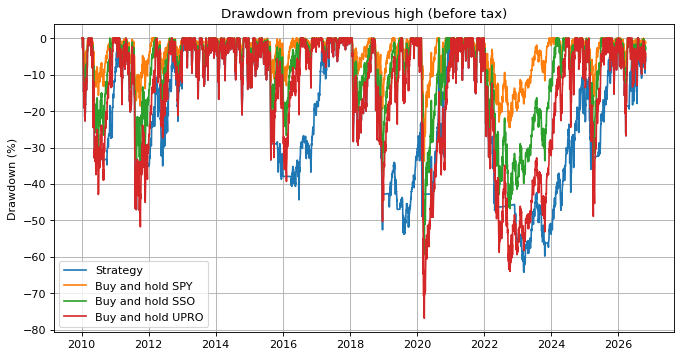

In [6]:
plt.figure(figsize=(10,5))
for name in runs:
    plt.plot(with_tax[name].index, with_tax[name]["value"], label=name)
plt.yscale("log")
plt.title("Growth of $10,000 after taxes paid each year (testing period, log scale)")
plt.ylabel("Account value")
plt.legend()
plt.grid(True)
plt.show()

def drawdown_series(returns):
    growth = (1 + returns).cumprod()
    return growth / growth.cummax() - 1

plt.figure(figsize=(10,5))
for name in ["Strategy", "Buy and hold SPY", "Buy and hold SSO", "Buy and hold UPRO"]:
    plt.plot(pre_tax[name].index, drawdown_series(pre_tax[name]["strategy_return"]) * 100, label=name)
plt.title("Drawdown from previous high (before tax)")
plt.ylabel("Drawdown (%)")
plt.legend()
plt.grid(True)
plt.savefig("../images/drawdowns_2010.png", dpi=150, bbox_inches="tight")
plt.show()

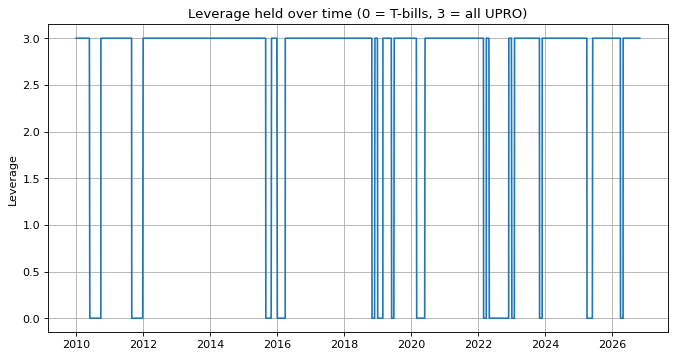

Time at 3x: 83.6%
Time in T-bills: 16.4%
Years the strategy beat buy and hold SSO (before tax): 8 out of 17


,Strategy,Buy and hold SSO,Buy and hold SPY
Date,,,
2010,0.089,0.228,0.131
2011,-0.177,-0.029,0.019
2012,0.400,0.310,0.160
2013,1.185,0.705,0.323
2014,0.380,0.255,0.135
2015,-0.281,-0.012,0.012
2016,0.215,0.213,0.120
2017,0.714,0.444,0.217
2018,-0.285,-0.146,-0.046


In [7]:
# leverage held over time
held_beta = strategy_test["w_SPY"] + 2 * strategy_test["w_SSO"] + 3 * strategy_test["w_UPRO"]

plt.figure(figsize=(10,5))
plt.plot(held_beta.index, held_beta)
plt.title("Leverage held over time (0 = T-bills, 3 = all UPRO)")
plt.ylabel("Leverage")
plt.grid(True)
plt.show()

print("Time at 3x:", str(round((held_beta > 2.9).mean() * 100, 1)) + "%")
print("Time in T-bills:", str(round((held_beta < 0.1).mean() * 100, 1)) + "%")

yearly = pd.DataFrame({
    "Strategy": (1 + strategy_test["strategy_return"]).groupby(strategy_test.index.year).prod() - 1,
    "Buy and hold SSO": (1 + pre_tax["Buy and hold SSO"]["strategy_return"]).groupby(strategy_test.index.year).prod() - 1,
    "Buy and hold SPY": (1 + pre_tax["Buy and hold SPY"]["strategy_return"]).groupby(strategy_test.index.year).prod() - 1,
})
yearly = yearly.loc[yearly.index >= 2010]
print("Years the strategy beat buy and hold SSO (before tax):", int((yearly["Strategy"] > yearly["Buy and hold SSO"]).sum()), "out of", len(yearly))
yearly

## 4. Walk-forward (2000 to now)

Every January I score all 42 combinations from 1994 through the end of the previous year (growth after the taxes paid each year) and trade the best one for the next 12 months. Trading starts in 2000, so it has to get through the dot com crash.

This section makes Figure 1 (`images/walk_forward_2000.png`), the walk-forward column of Table 3, and Table 4 in the README.

In [8]:
walk_weights, picks = walk_forward(data, settings_list)
print("Setting picked each year:")
print(picks.to_string())

Setting picked each year:
       trend sizing  size vol_source    check
year                                         
2000    none  fixed 3.000   realized  monthly
2001    none  fixed 3.000   realized  monthly
2002  sma200  fixed 3.000   realized  monthly
2003  sma200  fixed 3.000   realized  monthly
2004  sma200  fixed 3.000   realized  monthly
2005  sma200  fixed 3.000   realized  monthly
2006  sma200  fixed 3.000   realized  monthly
2007  sma200  fixed 3.000   realized  monthly
2008  sma200  fixed 3.000   realized  monthly
2009  sma200  fixed 3.000   realized  monthly
2010  sma200  fixed 3.000   realized  monthly
2011  sma200  fixed 3.000   realized  monthly
2012  sma200  fixed 3.000   realized  monthly
2013  sma200  fixed 3.000   realized  monthly
2014  sma200  fixed 3.000   realized  monthly
2015  sma200  fixed 3.000   realized  monthly
2016  sma200  fixed 3.000   realized  monthly
2017  sma200  fixed 3.000   realized  monthly
2018  sma200  fixed 3.000   realized  monthly
2019  sm

In [9]:
# same signals, different start years
rows = []
for start in ["2000-01-01", "2005-01-01", "2008-01-01", "2010-01-01", "2015-01-01", "2020-01-01"]:
    strat = simulate(data, walk_weights, start=start, taxes=True)
    row = {"start": start, "strategy_after_tax_cagr": after_tax_cagr(strat),
           "strategy_max_drawdown": get_stats(simulate(data, walk_weights, start=start)["strategy_return"],
                                              strat["tbill_return"], strat["spy_return"])["max_drawdown"]}
    for ticker in ["SPY", "SSO", "UPRO"]:
        row[ticker + "_after_tax_cagr"] = after_tax_cagr(run_fixed(data, {ticker: 1.0}, start=start, taxes=True))
    row["beats_SPY"] = row["strategy_after_tax_cagr"] > row["SPY_after_tax_cagr"]
    row["beats_SSO"] = row["strategy_after_tax_cagr"] > row["SSO_after_tax_cagr"]
    rows.append(row)

by_start = pd.DataFrame(rows).set_index("start")
by_start

,strategy_after_tax_cagr,strategy_max_drawdown,SPY_after_tax_cagr,SSO_after_tax_cagr,UPRO_after_tax_cagr,beats_SPY,beats_SSO
start,,,,,,,
2000-01-01,0.098,-0.822,0.075,0.084,0.064,True,True
2005-01-01,0.146,-0.642,0.099,0.137,0.148,True,True
2008-01-01,0.156,-0.642,0.103,0.146,0.156,True,True
2010-01-01,0.145,-0.642,0.129,0.215,0.278,True,False
2015-01-01,0.096,-0.642,0.123,0.193,0.236,False,False
2020-01-01,0.139,-0.642,0.134,0.194,0.217,True,False


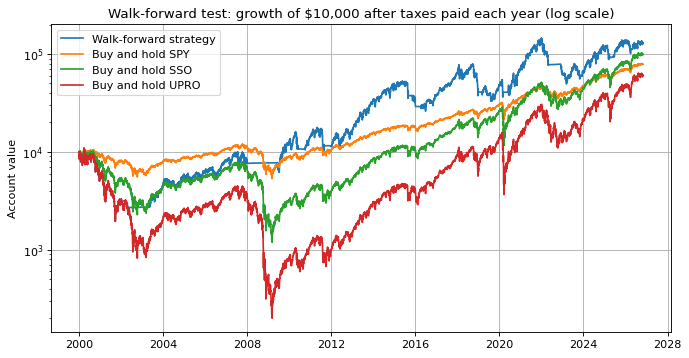

,Walk-forward strategy,Buy and hold SPY,Buy and hold SSO,Buy and hold UPRO
value_before_tax,"182,474.055","84,589.238","104,153.797","61,352.836"
value_after_tax_sold,"121,386.602","69,792.962","86,467.499","53,118.347"
cagr_before_tax,0.115,0.083,0.091,0.070
cagr_after_tax,0.098,0.075,0.084,0.064
volatility,0.395,0.192,0.380,0.576
sharpe,0.426,0.412,0.371,0.375
max_drawdown,-0.822,-0.552,-0.888,-0.982
beta,1.408,1.000,1.969,2.994


In [10]:
wf_start = "2000-01-01"
walk_pre = {
    "Walk-forward strategy": simulate(data, walk_weights, start=wf_start),
    "Buy and hold SPY": run_fixed(data, {"SPY": 1.0}, start=wf_start),
    "Buy and hold SSO": run_fixed(data, {"SSO": 1.0}, start=wf_start),
    "Buy and hold UPRO": run_fixed(data, {"UPRO": 1.0}, start=wf_start),
}
walk_tax = {
    "Walk-forward strategy": simulate(data, walk_weights, start=wf_start, taxes=True),
    "Buy and hold SPY": run_fixed(data, {"SPY": 1.0}, start=wf_start, taxes=True),
    "Buy and hold SSO": run_fixed(data, {"SSO": 1.0}, start=wf_start, taxes=True),
    "Buy and hold UPRO": run_fixed(data, {"UPRO": 1.0}, start=wf_start, taxes=True),
}

walk_table = make_table(walk_pre, walk_tax)

plt.figure(figsize=(10,5))
for name in walk_tax:
    plt.plot(walk_tax[name].index, walk_tax[name]["value"], label=name)
plt.yscale("log")
plt.title("Walk-forward test: growth of $10,000 after taxes paid each year (log scale)")
plt.ylabel("Account value")
plt.legend()
plt.grid(True)
plt.savefig("../images/walk_forward_2000.png", dpi=150, bbox_inches="tight")
plt.show()

walk_table

## 5. Does it only work at 200 days?

The papers say anywhere from 200-300 days works. If the result only shows up at exactly 200, it's probably luck, so this runs the same rule from 100 to 300 days at 2x and 3x, from 2000 on. I didn't use this table to pick anything.

This is Table 5 in the README.

In [11]:
sens = {}
for leverage in [2.0, 3.0]:
    row = {}
    for days in [100, 150, 200, 250, 300]:
        weights = get_target_weights(data, "sma200", "fixed", leverage, "realized", "monthly", sma_days=days)
        bt = simulate(data, weights, start=wf_start, taxes=True)
        row[str(days) + " days"] = after_tax_cagr(bt)
    sens[str(int(leverage)) + "x"] = row
sens = pd.DataFrame(sens).T

print("After-tax CAGR from 2000 on (buy and hold SSO:", str(round(walk_table.loc["cagr_after_tax", "Buy and hold SSO"] * 100, 1)) + "%)")
sens

After-tax CAGR from 2000 on (buy and hold SSO: 8.4%)


,100 days,150 days,200 days,250 days,300 days
2x,0.068,0.107,0.105,0.116,0.095
3x,0.080,0.138,0.133,0.147,0.110


## 6. Extra checks

### Trade timing

How much does it matter which day the trade goes in? Same close isn't actually possible (that was the mistake in my first version), next day is what I use everywhere, and two days later is just there to see how sensitive it is.

This is README Section 6.5.

In [12]:
rows = []
for lag in [0, 1, 2]:
    row = {"trade_delay_days": lag}
    for start in ["2000-01-01", "2010-01-01"]:
        bt = simulate(data, walk_weights if start == "2000-01-01" else get_target_weights(data, **s), start=start, taxes=True, lag=lag)
        row["after_tax_cagr_from_" + start[:4]] = after_tax_cagr(bt)
    rows.append(row)
pd.DataFrame(rows).set_index("trade_delay_days")

,after_tax_cagr_from_2000,after_tax_cagr_from_2010
trade_delay_days,,
0,0.112,0.172
1,0.098,0.145
2,0.107,0.157


### Rebuilt UPRO vs real UPRO

UPRO only exists since June 25, 2009, so everything before that is rebuilt. This splits the before-tax results at that date.

This is README Section 6.1.

In [13]:
first_upro = data["first_date"]["UPRO"]
rows = []
for label, start, end in [("Rebuilt UPRO (2000 to Jun 2009)", "2000-01-01", first_upro),
                          ("Real UPRO (Jun 2009 to now)", first_upro + pd.Timedelta(days=1), None)]:
    row = {"period": label}
    for name, bt in [("strategy", simulate(data, walk_weights, start=start, end=end)),
                     ("SPY", run_fixed(data, {"SPY": 1.0}, start=start, end=end)),
                     ("SSO", run_fixed(data, {"SSO": 1.0}, start=start, end=end)),
                     ("UPRO", run_fixed(data, {"UPRO": 1.0}, start=start, end=end))]:
        row[name + "_cagr_before_tax"] = get_stats(bt["strategy_return"], bt["tbill_return"], bt["spy_return"])["cagr"]
    rows.append(row)
pd.DataFrame(rows).set_index("period")

,strategy_cagr_before_tax,SPY_cagr_before_tax,SSO_cagr_before_tax,UPRO_cagr_before_tax
period,,,,
Rebuilt UPRO (2000 to Jun 2009),-0.035,-0.030,-0.148,-0.277
Real UPRO (Jun 2009 to now),0.199,0.148,0.244,0.318


### Rolling window walk-forward

The walk-forward above scores every year back to 1994, so 2000-2002 and 2008 stay in the score forever, which is probably why it picks the same rule every year. This version only looks at the last 5 years when it picks.

This is README Section 6.4.

In [14]:
rolling_weights, rolling_picks = walk_forward(data, settings_list, window_years=5)

def short_label(row):
    return row["trend"] + ", " + row["sizing"] + " " + str(row["size"]) + ", " + row["vol_source"] + ", " + row["check"]

print("Setting picked each year with a 5-year window:")
for year, row in rolling_picks.iterrows():
    print(" ", year, short_label(row))

rolling = simulate(data, rolling_weights, start=wf_start, taxes=True)
print()
print("After-tax CAGR from 2000, 5-year window:", str(round(after_tax_cagr(rolling) * 100, 2)) + "%")
print("After-tax CAGR from 2000, every year since 1994:", str(round(walk_table.loc["cagr_after_tax", "Walk-forward strategy"] * 100, 2)) + "%")
print("Max drawdown, 5-year window:", str(round(get_stats(simulate(data, rolling_weights, start=wf_start)["strategy_return"], rolling["tbill_return"], rolling["spy_return"])["max_drawdown"] * 100, 1)) + "%")

Setting picked each year with a 5-year window:
  2000 none, fixed 3.0, realized, monthly
  2001 none, fixed 3.0, realized, monthly
  2002 sma200, fixed 3.0, realized, monthly
  2003 sma200, kelly 0.5, vix, monthly
  2004 sma200, fixed 3.0, realized, monthly
  2005 sma200, fixed 3.0, realized, monthly
  2006 sma200, fixed 3.0, realized, daily
  2007 sma200, fixed 3.0, realized, monthly
  2008 sma200, fixed 3.0, realized, monthly
  2009 sma200, fixed 3.0, realized, monthly
  2010 sma10m, fixed 3.0, realized, monthly
  2011 sma200, fixed 3.0, realized, monthly
  2012 sma200, fixed 3.0, realized, monthly
  2013 sma200, fixed 3.0, realized, monthly
  2014 none, fixed 3.0, realized, monthly
  2015 none, fixed 3.0, realized, monthly
  2016 none, fixed 3.0, realized, monthly
  2017 none, fixed 3.0, realized, monthly
  2018 none, fixed 3.0, realized, monthly
  2019 none, fixed 3.0, realized, monthly
  2020 none, fixed 3.0, realized, monthly
  2021 none, fixed 3.0, realized, monthly
  2022 none,

### Is it actually significant?

Three checks:
- a t-test on the yearly return gap vs the benchmark (roughly, I'd want t > 2)
- the standard error of the Sharpe ratio (Lo 2002)
- the deflated Sharpe ratio (Bailey and Lopez de Prado 2014), which is the chance the true Sharpe is above 0 after adjusting for fat tails and for how many settings I tried. The "luck hurdle" is the Sharpe you'd expect the best of that many settings to get by pure luck.

I ran it with 42 trials (this version) and 277 (the whole project: 96 in v1, 126 in v2, 13 in a technical indicator version I dropped, and 42 here). A lot of those settings are really similar, so the true number of independent tries is somewhere in between.

This is README Section 6.2.

In [15]:
from strategy import significance

walk_pre_returns = walk_pre["Walk-forward strategy"]["strategy_return"]
cash = walk_pre["Walk-forward strategy"]["tbill_return"]

trial_sharpes = []
for settings in settings_list:
    bt = run_strategy(data, settings, start=wf_start)
    excess = bt["strategy_return"] - bt["tbill_return"]
    trial_sharpes.append(excess.mean() / excess.std())

rows = {}
for benchmark in ["SPY", "SSO"]:
    bench = walk_pre["Buy and hold " + benchmark]["strategy_return"].reindex(walk_pre_returns.index).fillna(0)
    for n_trials in [42, 277]:
        rows["vs " + benchmark + ", " + str(n_trials) + " trials"] = significance(walk_pre_returns, bench, cash, n_trials, trial_sharpes)
pd.DataFrame(rows)

,"vs SPY, 42 trials","vs SPY, 277 trials","vs SSO, 42 trials","vs SSO, 277 trials"
years,26.000,26.000,26.000,26.000
average_yearly_gap,0.107,0.107,0.047,0.047
years_ahead,15.000,15.000,14.000,14.000
t_stat_yearly_gap,1.659,1.659,0.912,0.912
sharpe,0.426,0.426,0.426,0.426
sharpe_standard_error,0.202,0.202,0.202,0.202
prob_sharpe_above_0,0.986,0.986,0.986,0.986
luck_hurdle_sharpe,0.150,0.195,0.150,0.195
deflated_sharpe_prob,0.921,0.882,0.921,0.882


### Monte Carlo that re-runs the rule

This builds 1,000 new 10-year S&P 500 paths out of random blocks of SPY's real daily returns since 1993 (with the T-bill rate and VIX from the same days), rebuilds SSO and UPRO from each path, and re-runs the rule on each one. Unlike my first version, the trend filter can actually fail here.

Although, stitching random blocks together breaks up any trend longer than one block, and trend filters depend on long trends, so this is a tough test for it. I ran it with 6-month and 1-year blocks to see how much that matters. Before tax.

This is README Section 6.3.

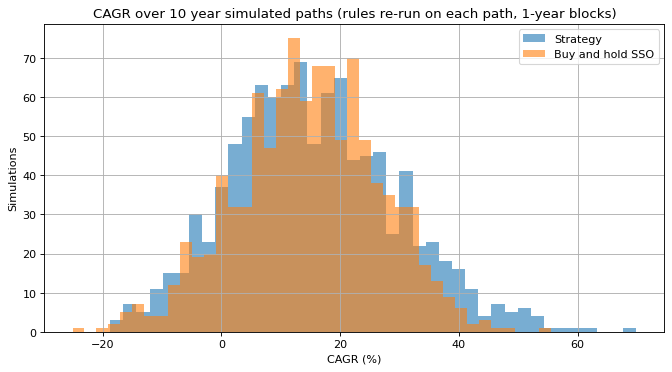

,126-day blocks,252-day blocks
chance_beats_SPY,0.553,0.649
chance_beats_SSO,0.414,0.510
median_cagr_strategy,0.115,0.144
median_cagr_SPY,0.109,0.112
median_cagr_SSO,0.142,0.149
median_max_drawdown_strategy,-0.675,-0.618
median_max_drawdown_SSO,-0.596,-0.590
worst_5pct_cagr_strategy,-0.098,-0.061
worst_5pct_cagr_SSO,-0.037,-0.058


In [16]:
mc_rows = {}
for block in [126, 252]:
    mc = strategy.rule_monte_carlo(data, s, years=10, block_size=block, sims=1000)
    mc_rows[str(block) + "-day blocks"] = {
        "chance_beats_SPY": (mc["strategy_cagr"] > mc["spy_cagr"]).mean(),
        "chance_beats_SSO": (mc["strategy_cagr"] > mc["sso_cagr"]).mean(),
        "median_cagr_strategy": mc["strategy_cagr"].median(),
        "median_cagr_SPY": mc["spy_cagr"].median(),
        "median_cagr_SSO": mc["sso_cagr"].median(),
        "median_max_drawdown_strategy": mc["strategy_drawdown"].median(),
        "median_max_drawdown_SSO": mc["sso_drawdown"].median(),
        "worst_5pct_cagr_strategy": mc["strategy_cagr"].quantile(0.05),
        "worst_5pct_cagr_SSO": mc["sso_cagr"].quantile(0.05),
    }
    last_mc = mc

plt.figure(figsize=(10,5))
plt.hist(last_mc["strategy_cagr"] * 100, bins=40, alpha=0.6, label="Strategy")
plt.hist(last_mc["sso_cagr"] * 100, bins=40, alpha=0.6, label="Buy and hold SSO")
plt.title("CAGR over 10 year simulated paths (rules re-run on each path, 1-year blocks)")
plt.xlabel("CAGR (%)")
plt.ylabel("Simulations")
plt.legend()
plt.grid(True)
plt.show()

pd.DataFrame(mc_rows)

### Outside the US

Same rule (200 days, 3x, monthly, next-day trades) on Japan's Nikkei 225 and Germany's DAX. There aren't 2x/3x funds or local T-bill data going back that far, so this is a simpler before-tax version: 2x and 3x are rebuilt the same way, cash earns 0% and borrowing only costs the spread (see `index_data` in `strategy.py`). The Nikkei is price only, the DAX includes dividends.

This is Table 6 in the README (Section 6.7).

In [17]:
from strategy import index_data

rows = []
for name, file in [("Nikkei 225", "../data/N225.csv"), ("DAX", "../data/GDAXI.csv")]:
    index = index_data(file)
    for start in ["1994-01-01", "2000-01-01", "2010-01-01"]:
        row = {"index": name, "start": start}
        for label, bt in [("rule_3x", run_strategy(index, s, start=start)),
                          ("rule_2x", run_strategy(index, dict(s, size=2.0), start=start)),
                          ("hold_1x", run_fixed(index, {"SPY": 1.0}, start=start)),
                          ("hold_2x", run_fixed(index, {"SSO": 1.0}, start=start)),
                          ("hold_3x", run_fixed(index, {"UPRO": 1.0}, start=start))]:
            row[label + "_cagr"] = (bt["value"].iloc[-1] / start_value) ** (trading_days / len(bt)) - 1
            if label in ["rule_3x", "hold_2x"]:
                row[label + "_max_dd"] = strategy.max_drawdown(bt["strategy_return"])
        rows.append(row)
pd.DataFrame(rows).set_index(["index", "start"])

rule_3x_cagr  ...  hold_3x_cagr
index      start                     ...              
Nikkei 225 1994-01-01         0.035  ...        -0.061
           2000-01-01         0.066  ...        -0.048
           2010-01-01         0.071  ...         0.177
DAX        1994-01-01         0.134  ...         0.055
           2000-01-01         0.115  ...        -0.022
           2010-01-01         0.060  ...         0.132

[6 rows x 7 columns]

## 7. Worst stretches

3x leverage that only checks once a month is going to get hit hard by fast crashes. Worst months since 2000:

The worst single day here is the one mentioned in README Section 7.1.

In [18]:
walk_returns = walk_pre["Walk-forward strategy"]["strategy_return"]
monthly = (1 + walk_returns).groupby(walk_returns.index.to_period("M")).prod() - 1
spy_monthly = (1 + walk_pre["Buy and hold SPY"]["strategy_return"]).groupby(walk_returns.index.to_period("M")).prod() - 1

worst = pd.DataFrame({"Strategy": monthly, "SPY": spy_monthly}).sort_values("Strategy").head(8)
print("Worst single day for the strategy:", str(round(walk_returns.min() * 100, 1)) + "%", "on", walk_returns.idxmin().date())
print("For reference, the S&P 500 fell 20.5% on October 19, 1987. At 3x that would have been about -60% in one day.")
worst

Worst single day for the strategy: -19.8% on 2011-08-08
For reference, the S&P 500 fell 20.5% on October 19, 1987. At 3x that would have been about -60% in one day.


,Strategy,SPY
Date,,
2018-12,-0.289,-0.088
2001-02,-0.274,-0.095
2022-04,-0.260,-0.088
2001-09,-0.247,-0.082
2010-05,-0.242,-0.079
2020-02,-0.230,-0.079
2000-11,-0.226,-0.075
2011-08,-0.211,-0.055


## Findings

(Data through October 29, 2026. Next-day trades, wash sale rule, leveraged ETF payouts taxed as ordinary income, no outside-income tax credit.)

In the training years (2000-2009), the trend filter mattered more than anything else. Without one, the average after-tax CAGR was -7.9% a year, compared to +3.8% with the 200-day average and +7.0% with the 10-month average. Checking once a month also beat weekly and daily (+2.5% vs -3.4% and -3.1% on average), which lines up with Clare et al. (2013). The Kelly / volatility scaling rules actually did worse than just holding 3x when the trend was up, which lines up with Cederburg et al. (2020). The winner was 3x above the 200-day average at month end and T-bills below it, which is also the most leverage I allowed.

With that setting locked in, it made 14.5% a year after tax from 2010 on, vs 12.9% for SPY, 21.5% for SSO and 27.8% for UPRO, with a -64% max drawdown. So it beat SPY, but not leveraged buy and hold.

The walk-forward from 2000 is where it looks best. $10,000 turned into about $121,400 after tax, compared to $86,500 for SSO, $69,800 for SPY and $53,100 for UPRO (9.8% vs 8.4%, 7.5% and 6.4% a year). Even though that's the best ending number of anything here, it fell 82% along the way. Specifically, scoring 1994-1999 picked plain 3x buy and hold for 2000 and 2001, right into the dot com crash, and it only switched to the trend filter in 2002.

With later start years, the edge shrinks or flips. From 2005 it made 14.6% vs 13.7% for SSO, but UPRO made 14.8%. From 2010, 2015 and 2020 it trailed SSO, and from 2015 it even trailed SPY (9.6% vs 12.3%).

The extra checks mostly went against it. Trading at the signal's own close made 11.2% a year from 2000, while the next day makes 9.8% and two days later makes 10.7%, which is a big swing for a one-day difference. Splitting at the date UPRO started trading was even worse for it. In the rebuilt years (2000 to June 2009) the strategy lost 3.5% a year before tax vs -14.8% for SSO, but since UPRO actually started trading, it made 19.9% a year vs 24.4% for SSO and 31.8% for UPRO. This means all of the edge over leveraged buy and hold comes from years where UPRO had to be rebuilt.

The significance tests weren't convincing either. The average yearly lead over SPY was about 10.7 points (t = 1.7), and over SSO about 4.7 points (t = 0.9), so neither gets to 2. The deflated Sharpe ratio says the Sharpe (0.43) is very likely above 0 even after accounting for everything I tried (88-92%). On the other hand, SPY's Sharpe over the same years was about the same (0.41), so that doesn't really show the strategy is better.

The rolling window version only looks at the last 5 years, and that switched it to plain 3x buy and hold from 2014-2022. It ended at 10.3% a year, also with an -82% drawdown. So the "same rule every year" result really just comes from always scoring back to 1994. In the Monte Carlo, over 1,000 new 10-year paths, it beat SPY 55-65% of the time but SSO only 41-51% of the time, and it usually had a bigger drawdown than SSO.

Outside the US, on the DAX and the Nikkei, the 3x rule beat holding 2x from 1994 or 2000 but lost badly from 2010 on. On the Nikkei from 1994, it actually did worse than holding the plain index (3.5% vs 4.2% a year before tax), with an -83% drawdown. The one check that went its way was the moving average length, since from 2000 every average from 150 to 300 days beat SSO (100 days didn't).

Overall, the 200-day 3x rule beat buy and hold SPY and SSO over stretches that include a long bear market, but mostly in years where UPRO had to be rebuilt. Since the real UPRO started trading it has trailed leveraged buy and hold. In addition, the lead isn't statistically strong, it depends on the exact trade day, and the drawdowns got to -82%. Simply put, I don't think this is a proven way to beat SSO. It's a high-risk rule that has helped in long crashes and lagged in long bull markets.

## Limitations

- This is a lot of risk. At 3x, a one-day crash like October 1987 (-20.5%) would cost about 60% in a day, and since it only checks at month end it would still be fully invested.
- There's no live forward test yet. Everything here, including the walk-forward, uses past data, so the real test is running `monthly_signal.py` going forward and keeping track.
- UPRO before June 2009 and SSO before June 2006 are rebuilt from SPY, not real prices.
- Trades fill at the next day's close. A real order would probably go in near the close or at the next open.
- Federal tax only. The wash sale rule is simplified (a disallowed loss gets added back in the year the replacement shares are bought, and the holding period doesn't carry over). Taxes come out in December instead of April.
- 3x was the most leverage I allowed and it won, so the result is partly just a bet on leverage. The grid can't tell whether more leverage would have been "better" (or a lot worse).
- The research these rules come from mostly covers 1928-2015, and both Cederburg et al. (2020) and Zakamulin (2014) found timing rules often lose some or all of their edge out of sample.

## Environment

This prints the package versions I last ran this notebook with, plus the data files it read. Yahoo goes back and changes old prices once in a while, so if your hashes don't match mine, your download is actually a little different from the one I used.

In [ ]:
import sys
import hashlib
import matplotlib
import yfinance

print("Python", sys.version.split()[0])
for module in [pd, np, matplotlib, yfinance]:
    print(module.__name__, module.__version__)
print()

for name in ["SPY", "SSO", "UPRO", "VIX", "N225", "GDAXI", "dtb3"]:
    path = "../data/" + name + ".csv"
    with open(path, "rb") as f:
        sha = hashlib.sha256(f.read()).hexdigest()[:12]
    last_row = pd.read_csv(path).iloc[-1, 0]
    print(name.ljust(6), "last row", last_row, " sha256", sha)